In [4]:
import pandas as pd
import numpy as np

# Load the original dataset
df = pd.read_csv("../data/raw/annapurna_data.csv")

# Display dataset shape
print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

Dataset shape: (180, 14)

Missing values:
date                   0
day_of_week            0
meal                   0
menu_main              0
exam_week              0
holiday_or_event       0
rain                   0
temperature_c          4
students_registered    0
plates_cooked          0
plates_eaten           4
leftover_kg            0
data_source            0
high_waste             0
dtype: int64

Total missing values: 8


In [5]:
# Make a copy so the original dataset stays unchanged
clean_df = df.copy()

# Check missing values before cleaning
print("Before cleaning:")
print(clean_df.isnull().sum())

# Fill missing temperature values with the median
temperature_median = clean_df["temperature_c"].median()

clean_df["temperature_c"] = clean_df["temperature_c"].fillna(
    temperature_median
)

# Remove rows where the target value is missing
clean_df = clean_df.dropna(subset=["plates_eaten"])

# Check missing values after cleaning
print("\nAfter cleaning:")
print(clean_df.isnull().sum())

print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)

print("\nTemperature median used:", temperature_median)

Before cleaning:
date                   0
day_of_week            0
meal                   0
menu_main              0
exam_week              0
holiday_or_event       0
rain                   0
temperature_c          4
students_registered    0
plates_cooked          0
plates_eaten           4
leftover_kg            0
data_source            0
high_waste             0
dtype: int64

After cleaning:
date                   0
day_of_week            0
meal                   0
menu_main              0
exam_week              0
holiday_or_event       0
rain                   0
temperature_c          0
students_registered    0
plates_cooked          0
plates_eaten           0
leftover_kg            0
data_source            0
high_waste             0
dtype: int64

Original dataset shape: (180, 14)
Cleaned dataset shape: (176, 14)

Temperature median used: 28.675


In [6]:
# Check for duplicate rows
duplicate_count = clean_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [7]:
# Columns to check for outliers
outlier_cols = ["plates_eaten", "leftover_kg", "temperature_c"]

# Detect outliers using IQR
for col in outlier_cols:
    Q1 = clean_df[col].quantile(0.25)
    Q3 = clean_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[col] < lower) | (clean_df[col] > upper)
    ]

    print(f"\nColumn: {col}")
    print(f"Lower limit: {lower:.2f}")
    print(f"Upper limit: {upper:.2f}")
    print(f"Number of outliers: {len(outliers)}")


Column: plates_eaten
Lower limit: 101.50
Upper limit: 233.50
Number of outliers: 1

Column: leftover_kg
Lower limit: -2.73
Upper limit: 9.45
Number of outliers: 0

Column: temperature_c
Lower limit: 19.05
Upper limit: 38.65
Number of outliers: 0


In [8]:
# Display the outlier in plates_eaten
Q1 = clean_df["plates_eaten"].quantile(0.25)
Q3 = clean_df["plates_eaten"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_rows = clean_df[
    (clean_df["plates_eaten"] < lower) |
    (clean_df["plates_eaten"] > upper)
]

print(outlier_rows[
    ["date", "meal", "menu_main", "students_registered",
     "plates_cooked", "plates_eaten", "leftover_kg", "data_source"]
].to_string(index=False))

      date      meal menu_main  students_registered  plates_cooked  plates_eaten  leftover_kg data_source
2026-10-23 Breakfast      Poha                  183            124         100.0         4.52   simulated


In [9]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd

# Select numeric input features
scale_cols = [
    "students_registered",
    "plates_cooked",
    "temperature_c"
]

# Normalization: values between 0 and 1
minmax = MinMaxScaler()

normalized = pd.DataFrame(
    minmax.fit_transform(clean_df[scale_cols]),
    columns=scale_cols,
    index=clean_df.index
)

# Standardization: mean approximately 0 and std approximately 1
standard = StandardScaler()

standardized = pd.DataFrame(
    standard.fit_transform(clean_df[scale_cols]),
    columns=scale_cols,
    index=clean_df.index
)

print("ORIGINAL DATA\n")
print(clean_df[scale_cols].describe().round(2))

print("\nNORMALIZED DATA (0 to 1)\n")
print(normalized.describe().round(2))

print("\nSTANDARDIZED DATA\n")
print(standardized.describe().round(2))

ORIGINAL DATA

       students_registered  plates_cooked  temperature_c
count               176.00         176.00         176.00
mean                215.54         189.23          28.75
std                  19.81          25.63           3.79
min                 180.00         108.00          19.36
25%                 200.00         175.75          26.40
50%                 215.00         190.00          28.68
75%                 233.25         207.25          31.30
max                 250.00         239.00          37.37

NORMALIZED DATA (0 to 1)

       students_registered  plates_cooked  temperature_c
count               176.00         176.00         176.00
mean                  0.51           0.62           0.52
std                   0.28           0.20           0.21
min                   0.00           0.00           0.00
25%                   0.29           0.52           0.39
50%                   0.50           0.63           0.52
75%                   0.76           0.76     

In [10]:
print("Standardized means:")
print(standardized.mean().round(4))

print("\nStandardized standard deviations:")
print(standardized.std(ddof=0).round(4))

Standardized means:
students_registered    0.0
plates_cooked          0.0
temperature_c          0.0
dtype: float64

Standardized standard deviations:
students_registered    1.0
plates_cooked          1.0
temperature_c          1.0
dtype: float64


In [11]:
# Inputs known BEFORE the meal is cooked
X = clean_df[
    [
        "day_of_week",
        "meal",
        "menu_main",
        "exam_week",
        "holiday_or_event",
        "rain",
        "temperature_c",
        "students_registered",
    ]
]

# Target: number of plates eaten
y = clean_df["plates_eaten"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five feature rows:")
print(X.head())

# Practical 6: Split into training, validation and testing
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("\nTrain:", X_train.shape[0], "rows")
print("Validation:", X_val.shape[0], "rows")
print("Test:", X_test.shape[0], "rows")

Feature shape: (176, 8)
Target shape: (176,)

First five feature rows:
  day_of_week       meal  menu_main  exam_week  holiday_or_event  rain  \
0     Tuesday  Breakfast       Poha          0                 0     1   
1     Tuesday      Lunch      Chole          0                 0     0   
2     Tuesday     Dinner  Pav Bhaji          0                 0     1   
3   Wednesday  Breakfast       Poha          0                 0     0   
4   Wednesday      Lunch   Dal Rice          0                 0     0   

   temperature_c  students_registered  
0          32.76                  194  
1          32.11                  235  
2          28.80                  191  
3          30.46                  218  
4          33.52                  212  

Train: 123 rows
Validation: 26 rows
Test: 27 rows


In [12]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify categorical and numerical columns
categorical_cols = ["day_of_week", "meal", "menu_main"]

numerical_cols = [
    "exam_week",
    "holiday_or_event",
    "rain",
    "temperature_c",
    "students_registered"
]

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numerical", "passthrough", numerical_cols)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nValidation shape:", X_val_processed.shape)
print("Test shape:", X_test_processed.shape)

Original training shape: (123, 8)
Processed training shape: (123, 27)

Validation shape: (26, 27)
Test shape: (27, 27)


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select only students_registered
X_train_simple = X_train[["students_registered"]]
X_val_simple = X_val[["students_registered"]]
X_test_simple = X_test[["students_registered"]]

# Create and train the model
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)

# Predict on validation data
y_val_pred = simple_model.predict(X_val_simple)

# Evaluate model
mae = mean_absolute_error(y_val, y_val_pred)
mse = mean_squared_error(y_val, y_val_pred)
r2 = r2_score(y_val, y_val_pred)

print("Simple Linear Regression Results")
print("--------------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("R2 Score:", round(r2, 4))

print("\nModel coefficient:", round(simple_model.coef_[0], 4))
print("Model intercept:", round(simple_model.intercept_, 4))

Simple Linear Regression Results
--------------------------------
MAE: 16.04
MSE: 379.19
R2 Score: 0.4342

Model coefficient: 0.5946
Model intercept: 38.0196


In [14]:
# Predict meal demand for different registration counts

new_students = pd.DataFrame({
    "students_registered": [150, 180, 200, 220, 250]
})

predictions = simple_model.predict(new_students)

for students, predicted in zip(
    new_students["students_registered"], predictions
):
    print(
        f"Registered: {students} | "
        f"Predicted plates eaten: {predicted:.2f}"
    )

Registered: 150 | Predicted plates eaten: 127.22
Registered: 180 | Predicted plates eaten: 145.05
Registered: 200 | Predicted plates eaten: 156.95
Registered: 220 | Predicted plates eaten: 168.84
Registered: 250 | Predicted plates eaten: 186.68


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# Identify categorical columns
cat_cols = ["day_of_week", "meal", "menu_main"]

# Convert categorical features into numerical features
preprocess = ColumnTransformer(
    [
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ],
    remainder="passthrough"
)

# Create the multiple linear regression pipeline
multi_model = Pipeline([
    ("prep", preprocess),
    ("reg", LinearRegression())
])

# Train the model
multi_model.fit(X_train, y_train)

# Predict using validation data
val_pred = multi_model.predict(X_val)

# Evaluate model
print("Multiple Linear Regression (Validation)")
print("--------------------------------------")
print("MAE:", round(mean_absolute_error(y_val, val_pred), 2))
print("MSE:", round(mean_squared_error(y_val, val_pred), 2))
print("R2:", round(r2_score(y_val, val_pred), 4))

print("\nSimple model baseline -> MAE: 16.04 | R2: 0.4342")

# Extract feature names and coefficients
names = multi_model.named_steps["prep"].get_feature_names_out()
coefs = multi_model.named_steps["reg"].coef_

# Create coefficient table
coef_table = pd.DataFrame({
    "feature": names,
    "coefficient": coefs
})

coef_table["abs_coef"] = coef_table["coefficient"].abs()

coef_table = coef_table.sort_values(
    "abs_coef",
    ascending=False
).drop(columns="abs_coef")

print("\nTop 8 influences:")
print(coef_table.head(8).round(2).to_string(index=False))

Multiple Linear Regression (Validation)
--------------------------------------
MAE: 11.55
MSE: 176.6
R2: 0.7365

Simple model baseline -> MAE: 16.04 | R2: 0.4342

Top 8 influences:
                    feature  coefficient
remainder__holiday_or_event       -44.28
    cat__day_of_week_Sunday       -21.67
       remainder__exam_week       -12.99
        cat__menu_main_Upma        -8.84
    cat__day_of_week_Monday         7.46
    cat__day_of_week_Friday         5.73
       cat__menu_main_Rajma         5.66
        cat__menu_main_Idli         5.47


In [16]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Polynomial Regression model (degree 2)
poly_model = Pipeline([
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("regression", LinearRegression())
])

# Use students_registered as the input
X_train_poly = X_train[["students_registered"]]
X_val_poly = X_val[["students_registered"]]

# Train the model
poly_model.fit(X_train_poly, y_train)

# Predict validation values
poly_pred = poly_model.predict(X_val_poly)

# Evaluate
print("Polynomial Regression Results (Validation)")
print("------------------------------------------")
print("MAE:", round(mean_absolute_error(y_val, poly_pred), 2))
print("MSE:", round(mean_squared_error(y_val, poly_pred), 2))
print("R2:", round(r2_score(y_val, poly_pred), 4))

print("\nSimple Linear Regression baseline:")
print("MAE: 16.04 | R2: 0.4342")

Polynomial Regression Results (Validation)
------------------------------------------
MAE: 16.37
MSE: 409.08
R2: 0.3896

Simple Linear Regression baseline:
MAE: 16.04 | R2: 0.4342


In [17]:
import numpy as np

# Actual and predicted values (small example)
actual = np.array([100, 120, 150, 180, 200])
predicted = np.array([105, 115, 145, 190, 195])

# Calculate errors
errors = actual - predicted

# Calculate Mean Squared Error manually
mse_manual = np.mean(errors ** 2)

# Calculate Mean Absolute Error manually
mae_manual = np.mean(np.abs(errors))

print("Actual values:", actual)
print("Predicted values:", predicted)
print("Errors:", errors)

print("\nMean Squared Error:", round(mse_manual, 2))
print("Mean Absolute Error:", round(mae_manual, 2))

Actual values: [100 120 150 180 200]
Predicted values: [105 115 145 190 195]
Errors: [ -5   5   5 -10   5]

Mean Squared Error: 40.0
Mean Absolute Error: 6.0


In [18]:
import pandas as pd, numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cat_cols = ["day_of_week", "meal", "menu_main"]
num_cols = ["temperature_c", "students_registered"]

# 1) Simple: students_registered only
simple = Pipeline([
    ("prep", ColumnTransformer([("num", "passthrough", ["students_registered"])])),
    ("reg", LinearRegression())])

# 2) Multiple: all features
multiple = Pipeline([
    ("prep", ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
        remainder="passthrough")),
    ("reg", LinearRegression())])

# 3) Polynomial (degree 2) on numeric features + encoded categories
poly = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", Pipeline([("sc", StandardScaler()),
                          ("poly", PolynomialFeatures(2, include_bias=False))]),
         num_cols)], remainder="passthrough")),
    ("reg", LinearRegression())])

rows = []
for name, m in [("Simple", simple), ("Multiple", multiple), ("Polynomial (deg 2)", poly)]:
    m.fit(X_train, y_train)
    p = m.predict(X_val)
    rows.append([name,
                 mean_absolute_error(y_val, p),
                 mean_squared_error(y_val, p),
                 r2_score(y_val, p)])

results = pd.DataFrame(rows, columns=["Model", "MAE", "MSE", "R2"]).round(3)
print(results.to_string(index=False))

             Model    MAE     MSE    R2
            Simple 16.044 379.187 0.434
          Multiple 11.549 176.596 0.737
Polynomial (deg 2) 11.775 182.471 0.728


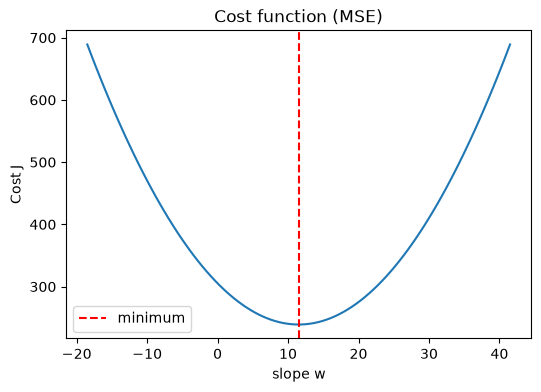

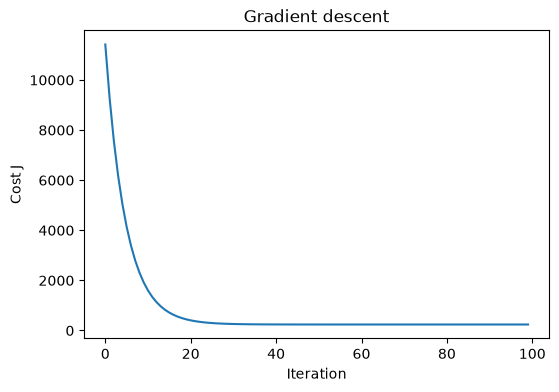

Gradient descent: w=11.51, b=165.73 | Closed form: w=11.51, b=165.73


In [19]:
import matplotlib.pyplot as plt

x = X_train["students_registered"].values
y = y_train.values
xs = (x - x.mean()) / x.std()          # standardize so gradient descent is stable

def cost(w, b):
    return np.mean((y - (w * xs + b)) ** 2) / 2   # MSE cost J(w, b)

# Closed-form best fit, used as the center of the plot
w_best, b_best = np.polyfit(xs, y, 1)

# 1) Cost vs slope (intercept fixed at best)
ws = np.linspace(w_best - 30, w_best + 30, 100)
plt.figure(figsize=(6, 4))
plt.plot(ws, [cost(w, b_best) for w in ws])
plt.axvline(w_best, color="red", linestyle="--", label="minimum")
plt.xlabel("slope w"); plt.ylabel("Cost J"); plt.title("Cost function (MSE)")
plt.legend(); plt.show()

# 2) Gradient descent: watch the cost fall
w, b, lr, history = 0.0, 0.0, 0.1, []
for _ in range(100):
    err = (w * xs + b) - y
    w -= lr * np.mean(err * xs)
    b -= lr * np.mean(err)
    history.append(cost(w, b))

plt.figure(figsize=(6, 4))
plt.plot(history)
plt.xlabel("Iteration"); plt.ylabel("Cost J"); plt.title("Gradient descent")
plt.show()
print(f"Gradient descent: w={w:.2f}, b={b:.2f} | Closed form: w={w_best:.2f}, b={b_best:.2f}")

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

# Same inputs as before (plates_cooked and leftover_kg are NOT included)
y_clf = clean_df["high_waste"]
yc_train, yc_val = y_clf.loc[X_train.index], y_clf.loc[X_val.index]

cat_cols = ["day_of_week", "meal", "menu_main"]
num_cols = ["temperature_c", "students_registered"]

logreg = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols)], remainder="passthrough")),
    ("clf", LogisticRegression(max_iter=1000))])

logreg.fit(X_train, yc_train)
pred = logreg.predict(X_val)

print("Class balance in train:\n", yc_train.value_counts())
print("\nAccuracy :", round(accuracy_score(yc_val, pred), 3))
print("Precision:", round(precision_score(yc_val, pred, zero_division=0), 3))
print("Recall   :", round(recall_score(yc_val, pred, zero_division=0), 3))
print("F1-score :", round(f1_score(yc_val, pred, zero_division=0), 3))
print("\nConfusion matrix:\n", confusion_matrix(yc_val, pred))

Class balance in train:
 high_waste
0    85
1    38
Name: count, dtype: int64

Accuracy : 0.5
Precision: 0.143
Recall   : 0.125
F1-score : 0.133

Confusion matrix:
 [[12  6]
 [ 7  1]]


In [21]:
# 1) Does high_waste actually vary with the inputs?
print(clean_df.groupby("meal")["high_waste"].mean().round(2))
print(clean_df.groupby("exam_week")["high_waste"].mean().round(2))
print(clean_df.groupby("day_of_week")["high_waste"].mean().round(2))

# 2) More reliable score: 5-fold stratified cross-validation, balanced classes
from sklearn.model_selection import cross_val_score, StratifiedKFold

logreg_bal = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols)], remainder="passthrough")),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_all = clean_df[X_train.columns]
for metric in ["accuracy", "recall", "f1"]:
    s = cross_val_score(logreg_bal, X_all, y_clf, cv=cv, scoring=metric)
    print(f"{metric}: {s.mean():.3f} (+/- {s.std():.3f})")

meal
Breakfast    0.33
Dinner       0.25
Lunch        0.36
Name: high_waste, dtype: float64
exam_week
0    0.33
1    0.24
Name: high_waste, dtype: float64
day_of_week
Friday       0.22
Monday       0.29
Saturday     0.43
Sunday       0.13
Thursday     0.30
Tuesday      0.46
Wednesday    0.35
Name: high_waste, dtype: float64
accuracy: 0.596 (+/- 0.105)
recall: 0.582 (+/- 0.093)
f1: 0.480 (+/- 0.097)


In [22]:
# New feature: how much more is cooked than students registered (known before the meal)
clf_df = clean_df.copy()
clf_df["cook_ratio"] = clf_df["plates_cooked"] / clf_df["students_registered"]

cat_cols = ["day_of_week", "meal", "menu_main"]
num_cols_new = ["temperature_c", "students_registered", "plates_cooked", "cook_ratio"]
feature_cols = cat_cols + ["exam_week", "holiday_or_event", "rain"] + num_cols_new

logreg_plan = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler(), num_cols_new)], remainder="passthrough")),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_plan, y_plan = clf_df[feature_cols], clf_df["high_waste"]
for metric in ["accuracy", "recall", "precision", "f1"]:
    s = cross_val_score(logreg_plan, X_plan, y_plan, cv=cv, scoring=metric)
    print(f"{metric}: {s.mean():.3f} (+/- {s.std():.3f})")

accuracy: 0.636 (+/- 0.093)
recall: 0.618 (+/- 0.134)
precision: 0.448 (+/- 0.094)
f1: 0.515 (+/- 0.105)


In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

def make_prep():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler(), num_cols_new)], remainder="passthrough")

models = {
    "Baseline (always No)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": SVC(class_weight="balanced"),
}

scoring = ["accuracy", "precision", "recall", "f1"]
rows = []
for name, clf in models.items():
    pipe = Pipeline([("prep", make_prep()), ("clf", clf)])
    res = cross_validate(pipe, X_plan, y_plan, cv=cv, scoring=scoring)
    rows.append([name] + [res[f"test_{m}"].mean() for m in scoring])

comparison = pd.DataFrame(rows, columns=["Model"] + [m.capitalize() for m in scoring]).round(3)
print(comparison.to_string(index=False))

c:\Users\poona\OneDrive\Desktop\annapurna-ml\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\poona\OneDrive\Desktop\annapurna-ml\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\poona\OneDrive\Desktop\annapurna-ml\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

               Model  Accuracy  Precision  Recall    F1
Baseline (always No)     0.687      0.000   0.000 0.000
 Logistic Regression     0.636      0.448   0.618 0.515
           KNN (k=5)     0.630      0.360   0.200 0.248
         Naive Bayes     0.545      0.365   0.582 0.442
           SVM (RBF)     0.659      0.476   0.655 0.549


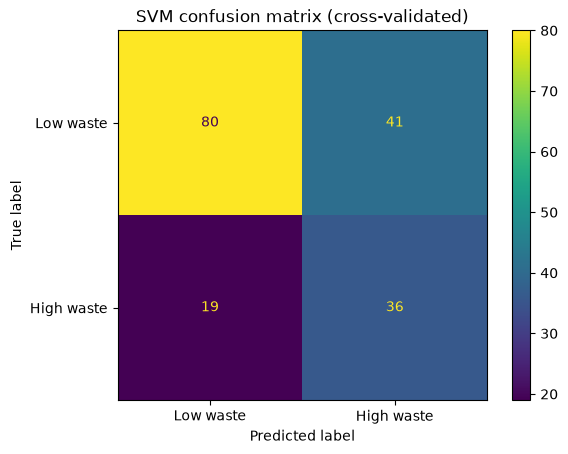

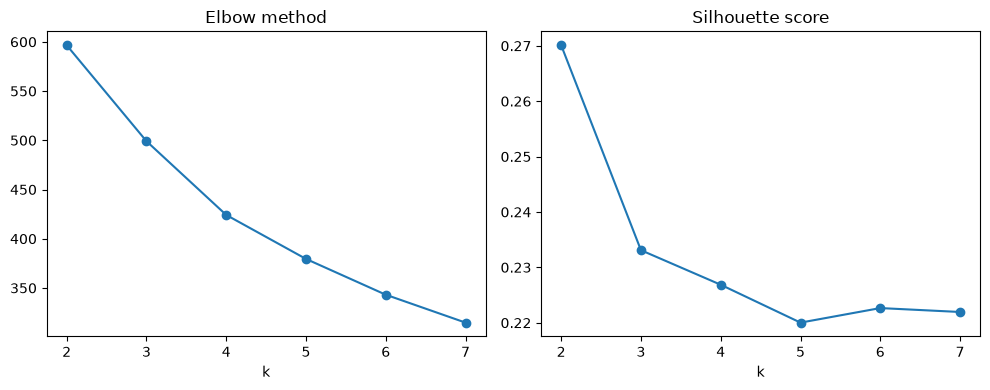

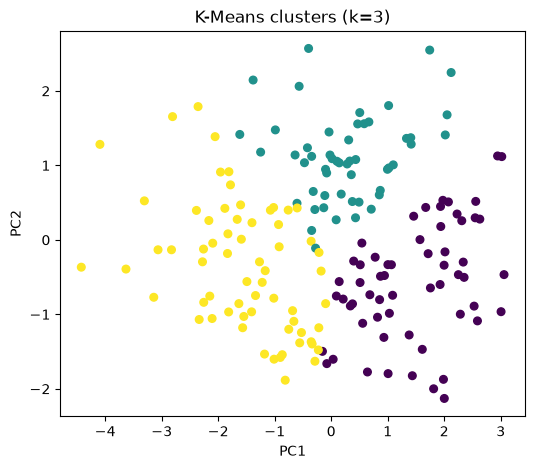

         students_registered  plates_cooked  plates_eaten  leftover_kg  \
cluster                                                                  
0                     231.76         209.76        191.97         2.81   
1                     219.96         194.50        160.38         5.56   
2                     197.28         166.38        151.77         2.32   

         temperature_c  high_waste  
cluster                             
0                29.76        0.17  
1                29.41        0.79  
2                27.32        0.06  

Meals per cluster:
 meal     Breakfast  Dinner  Lunch
cluster                          
0               21      18     20
1               20      13     19
2               19      26     20


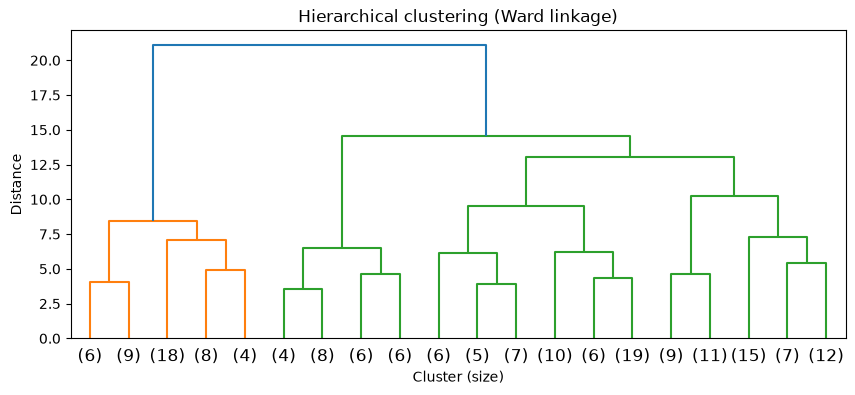

In [24]:
# ---- SVM confusion matrix (from cross-validation predictions) ----
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

svm_pipe = Pipeline([("prep", make_prep()),
                     ("clf", SVC(class_weight="balanced"))])
svm_pred = cross_val_predict(svm_pipe, X_plan, y_plan, cv=cv)
ConfusionMatrixDisplay(confusion_matrix(y_plan, svm_pred),
                       display_labels=["Low waste", "High waste"]).plot()
plt.title("SVM confusion matrix (cross-validated)")
plt.show()

# ---- K-Means ----
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

cluster_cols = ["students_registered", "plates_cooked", "plates_eaten",
                "leftover_kg", "temperature_c"]
Xc = StandardScaler().fit_transform(clean_df[cluster_cols])

# Elbow + silhouette to choose k
ks = range(2, 8)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xc).inertia_ for k in ks]
sil = [silhouette_score(Xc, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xc))
       for k in ks]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, marker="o");     ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

# Fit with k=3 (change after looking at the plots)
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=42)
clean_df = clean_df.assign(cluster=km.fit_predict(Xc))

# 2D view with PCA
pts = PCA(n_components=2).fit_transform(Xc)
plt.figure(figsize=(6, 5))
plt.scatter(pts[:, 0], pts[:, 1], c=clean_df["cluster"], cmap="viridis", s=30)
plt.title(f"K-Means clusters (k={k})"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

# Cluster profiles: what does each group look like?
print(clean_df.groupby("cluster")[cluster_cols + ["high_waste"]].mean().round(2))
print("\nMeals per cluster:\n", pd.crosstab(clean_df["cluster"], clean_df["meal"]))

# ---- Hierarchical clustering (dendrogram) ----
from scipy.cluster.hierarchy import linkage, dendrogram
plt.figure(figsize=(10, 4))
dendrogram(linkage(Xc, method="ward"), truncate_mode="lastp", p=20)
plt.title("Hierarchical clustering (Ward linkage)")
plt.xlabel("Cluster (size)"); plt.ylabel("Distance")
plt.show()

In [25]:
import joblib

# Rebuild full inputs and targets (the gradient descent cell had overwritten y)
X = clean_df[["day_of_week", "meal", "menu_main", "exam_week",
              "holiday_or_event", "rain", "temperature_c", "students_registered"]]
y = clean_df["plates_eaten"]
print("X:", X.shape, "| y:", y.shape)   # both should show 176

# Refit both final models on all data and save them for the app
multiple.fit(X, y)
svm_final = Pipeline([("prep", make_prep()),
                      ("clf", SVC(class_weight="balanced"))]).fit(X_plan, y_plan)

joblib.dump({
    "regressor": multiple,
    "classifier": svm_final,
    "options": {c: sorted(clean_df[c].unique().tolist())
                for c in ["day_of_week", "meal", "menu_main"]},
    "reg_features": list(X.columns),
    "clf_features": feature_cols,
}, "annapurna_models.joblib")
print("Saved annapurna_models.joblib")

X: (176, 8) | y: (176,)
Saved annapurna_models.joblib


In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

CSV_PATH = "../data/raw/annapurna_data.csv"   # <- change to your CSV location

# Same cleaning as before
df = pd.read_csv(CSV_PATH)
clean_df = df.copy()
clean_df["temperature_c"] = clean_df["temperature_c"].fillna(clean_df["temperature_c"].median())
clean_df = clean_df.dropna(subset=["plates_eaten"])

features = ["day_of_week", "meal", "menu_main", "exam_week", "holiday_or_event",
            "rain", "temperature_c", "students_registered"]
X, y = clean_df[features], clean_df["plates_eaten"]

# Same 70/15/15 split (random_state=42)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

cat_cols = ["day_of_week", "meal", "menu_main"]
model = Pipeline([
    ("prep", ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
        remainder="passthrough")),
    ("reg", LinearRegression())])

# Sanity check: this should match your earlier validation scores
model.fit(X_train, y_train)
vp = model.predict(X_val)
print("Check -> VAL MAE:", round(mean_absolute_error(y_val, vp), 2),
      "| VAL R2:", round(r2_score(y_val, vp), 3), "(expected about 11.55 and 0.737)")

# Final test score: train on train+validation, test once
tp = clone(model).fit(
    pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
).predict(X_test)
print("\nTEST rows:", len(y_test))
print("TEST MAE:", round(mean_absolute_error(y_test, tp), 2))
print("TEST MSE:", round(mean_squared_error(y_test, tp), 2))
print("TEST R2 :", round(r2_score(y_test, tp), 3))

Check -> VAL MAE: 11.55 | VAL R2: 0.737 (expected about 11.55 and 0.737)

TEST rows: 27
TEST MAE: 7.18
TEST MSE: 68.78
TEST R2 : 0.767
